True proportion = 0.18896
uniform bias = 0.0005350000000000077 SE = 0.011584080871965684 mean cost = 5000.0
walk bias = 0.002138529986861093 SE = 0.026001308140915374 mean cost = 1593.06


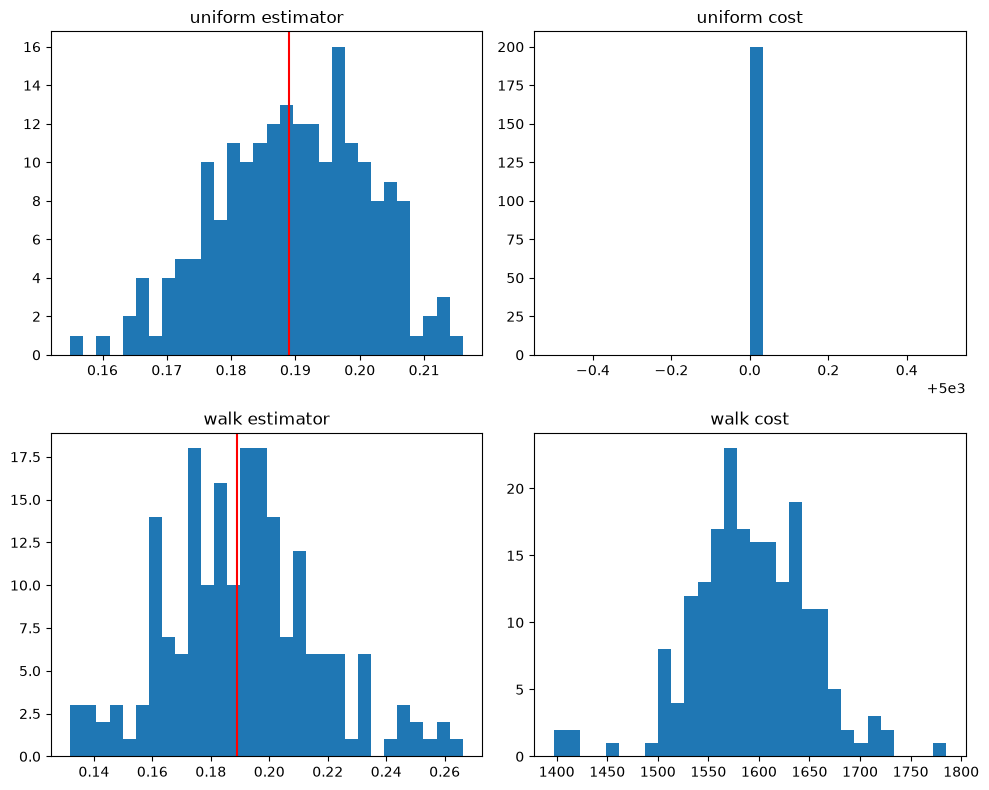

In [2]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

rng = np.random.default_rng(433)
g1 = nx.fast_gnp_random_graph(30000, 0.001, seed=433)
g2 = nx.fast_gnp_random_graph(20000, 0.005, seed=434)
g = nx.disjoint_union(g1, g2)

N = g.number_of_nodes()
deg = np.array([d for _, d in g.degree()])
nbrs = [list(g.neighbors(v)) for v in range(N)]
theta = np.mean(deg > 100)

n, reps, r = 1000, 200, 10

def uniform():
    Y = rng.integers(N, size=n)
    return np.mean(deg[Y] > 100), 5 * n

def walk():
    Y = []
    v = rng.integers(N)
    cost = 5
    for i in range(n):
        Y.append(v)
        if rng.random() < r / (r + deg[v]):
            v = rng.integers(N)
            cost += 5
        else:
            v = rng.choice(nbrs[v])
            cost += 1
    w = 1 / (r + deg[Y])
    return np.sum(w * (deg[Y] > 100)) / np.sum(w), cost

print("True proportion =", theta)
fig, ax = plt.subplots(2, 2, figsize=(10, 8))

for i, f in enumerate([uniform, walk]):
    res = np.array([f() for _ in range(reps)])
    est, cost = res[:, 0], res[:, 1]
    print(f.__name__, "bias =", est.mean() - theta, "SE =", est.std(ddof=1), "mean cost =", cost.mean())

    ax[i, 0].hist(est, bins=30)
    ax[i, 0].axvline(theta, color="red")
    ax[i, 0].set_title(f.__name__ + " estimator")
    ax[i, 1].hist(cost, bins=30)
    ax[i, 1].set_title(f.__name__ + " cost")

plt.tight_layout()
plt.show()